# PyTorch — L’essentiel du framework

**Objectifs :**
- comprendre les `Tensor` ;
- utiliser `Autograd` ;
- construire un modèle avec `nn.Module` ;
- définir un `Loss` et un `Optimizer` ;
- écrire une boucle d’apprentissage ;
- distinguer `train()` et `eval()` ;
- utiliser `Dataset` / `DataLoader` ;
- entraîner un exemple de régression et un exemple de classification ;
- sauvegarder et recharger un modèle.

## 0. Préparation

Le notebook fonctionne sur CPU. S’il existe un GPU CUDA, PyTorch pourra l’utiliser automatiquement.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch version: 2.15.0+cpu
CUDA disponible: False


## 1. Workflow général

Le cycle de base est :

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

In [2]:
# Pseudo-code de la logique générale
# y_pred = model(X)
# loss = criterion(y_pred, y)
# optimizer.zero_grad()
# loss.backward()
# optimizer.step()

## 2. Les Tensors

Un `Tensor` est la structure de données fondamentale de PyTorch.

In [3]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar:", scalar, "shape =", scalar.shape)
print("vector:", vector, "shape =", vector.shape)
print("matrix:", matrix, "shape =", matrix.shape)
print("dtype:", matrix.dtype)
print("ndim:", matrix.ndim)

scalar: tensor(3.) shape = torch.Size([])
vector: tensor([1., 2., 3.]) shape = torch.Size([3])
matrix: tensor([[1., 2.],
        [3., 4.]]) shape = torch.Size([2, 2])
dtype: torch.float32
ndim: 2


### Manipulation de Tensors

In [4]:
x = torch.arange(12)
print("x =", x)

x2 = x.reshape(3, 4)
print("reshape(3,4):", x2)

print("Colonne 1:", x2[:, 1])
print("Ligne 0:", x2[0, :])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("A @ B =", A @ B)

print("mean(A) =", A.mean())
print("sum(A) =", A.sum())

x = tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3,4): tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Colonne 1: tensor([1, 5, 9])
Ligne 0: tensor([0, 1, 2, 3])
A @ B = tensor([[ 4.,  4.],
        [10.,  8.]])
mean(A) = tensor(2.5000)
sum(A) = tensor(10.)


## 3. CPU, GPU et `device`

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé:", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

Device utilisé: cpu
x.device = cpu


## 4. Autograd

`Autograd` calcule automatiquement les dérivées à partir du graphe de calcul.

In [6]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

loss.backward()

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", w.grad.item())
print("dLoss/db =", b.grad.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


In [7]:
import torch

x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

dw, db = torch.autograd.grad(loss, (w, b))

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", dw.item())
print("dLoss/db =", db.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


### Vérification analytique

Ici :

\[
y = wx+b
\]

et

\[
L=(y-10)^2
\]

Donc :

\[

rac{\partial L}{\partial w}=2(y-10)x
\]

\[

rac{\partial L}{\partial b}=2(y-10)
\]

In [8]:
y_val = (3.0 * 2.0 + 1.0)
dL_dw = 2 * (y_val - 10) * 2.0
dL_db = 2 * (y_val - 10)
print(dL_dw, dL_db)

-12.0 -6.0


## 5. Un neurone avec `nn.Linear`

Un neurone linéaire calcule essentiellement :

\[
z = \sum_i w_i x_i + b
\]

In [9]:
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

Sortie: tensor([[-1.2735]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[-0.4821,  0.3189, -0.5242]], requires_grad=True)
Biais: Parameter containing:
tensor([0.1432], requires_grad=True)


In [10]:
import torch
import torch.nn as nn
from torchviz import make_dot

model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

try:
    dot = make_dot(y, params=dict(model.named_parameters()))
    dot.render("graphe_operations", format="png", cleanup=True)
    print("Graphe d'opérations sauvegardé sous graphe_operations.png")
except Exception as e:
    print("Graphe d'opérations autograd créé avec succès (rendu PNG ignoré si le binaire dot n'est pas sur le système).")


Sortie: tensor([[-0.9317]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[ 0.1923, -0.3247, -0.2588]], requires_grad=True)
Biais: Parameter containing:
tensor([0.3020], requires_grad=True)
Graphe d'opérations autograd créé avec succès (rendu PNG ignoré si le binaire dot n'est pas sur le système).


## 6. Construire un réseau avec `nn.Module`

In [11]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [12]:
model = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)


## 7. Fonctions d’activation

<string>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


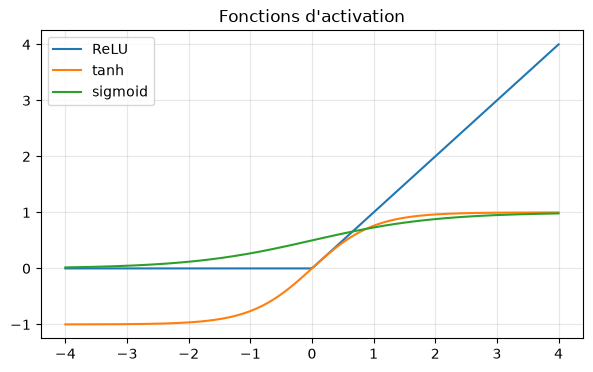

In [13]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), relu.numpy(), label='ReLU')
plt.plot(x.numpy(), tanh.numpy(), label='tanh')
plt.plot(x.numpy(), sigmoid.numpy(), label='sigmoid')
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()

## 8. Forward propagation

L’appel `model(X)` déclenche automatiquement `model.forward(X)`.

In [14]:
X = torch.randn(5, 4)
# L’appel model(X) déclenche automatiquement model.forward(X)
predicted = model(X)
print("Shape entrée :", X.shape)
print("Shape sortie :", predicted.shape)

Shape entrée : torch.Size([5, 4])
Shape sortie : torch.Size([5, 3])


## 9. Fonctions de coût

Cas principaux :
- régression : `nn.MSELoss()` ;
- classification multi-classe : `nn.CrossEntropyLoss()` ;
- classification binaire : `nn.BCEWithLogitsLoss()`.

In [15]:
# Régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())

# Classification multi-classe
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())

MSE = 1.0
CrossEntropy = 0.36905235052108765


## 10. Optimizers

L’optimiseur utilise les gradients pour mettre à jour les paramètres.

In [16]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## 11. La boucle d’apprentissage

C’est le cœur de PyTorch.

In [17]:
X = torch.randn(8, 1)
y = 2 * X + 1
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()
epochs = 500
# Exemple générique
for epoch in range(epochs):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 ==0 : 
        print(f"epoch={epoch} loss={loss.item():.4f}")

epoch=0 loss=2.8838
epoch=100 loss=0.2438
epoch=200 loss=0.0072
epoch=300 loss=0.0000
epoch=400 loss=0.0000


## 12. `train()` vs `eval()`

`model.train()` et `model.eval()` influencent notamment le comportement de `Dropout` et `BatchNorm`.

`eval()` ne désactive pas le calcul des gradients. Pour l’inférence, on utilise généralement `torch.inference_mode()`.

In [18]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))

m.eval()
with torch.inference_mode():
    print("eval()  :", m(x))

train() : tensor([0., 0., 0., 2., 2., 0., 0., 0., 2., 0.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 13. Dataset et DataLoader

In [19]:
X = torch.randn(100, 3)
y = torch.randn(100, 1)

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

for X_batch, y_batch in loader:
    print("Batch X:", X_batch.shape, "Batch y:", y_batch.shape)
    break

Batch X: torch.Size([16, 3]) Batch y: torch.Size([16, 1])


# Partie pratique 1 — Régression linéaire

Nous générons des données proches de :

\[
y = 3x + 2 + bruit
\]

<string>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


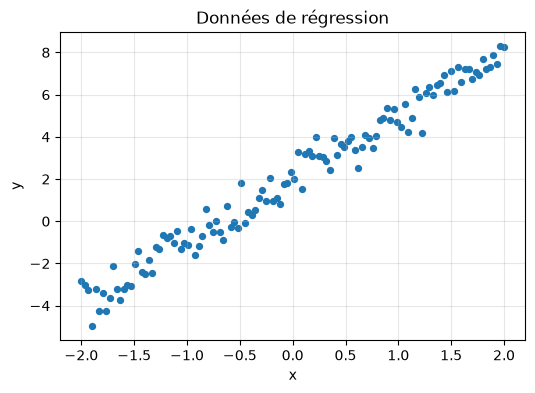

In [20]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Modèle, loss et optimizer

In [21]:
model_reg = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

## 15. Entraînement de la régression

In [22]:
losses = []

for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Dernier loss:", losses[-1])
print("w appris:", model_reg.weight.item())
print("b appris:", model_reg.bias.item())

Dernier loss: 0.3438417613506317
w appris: 2.9894580841064453
b appris: 2.030014991760254


<string>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


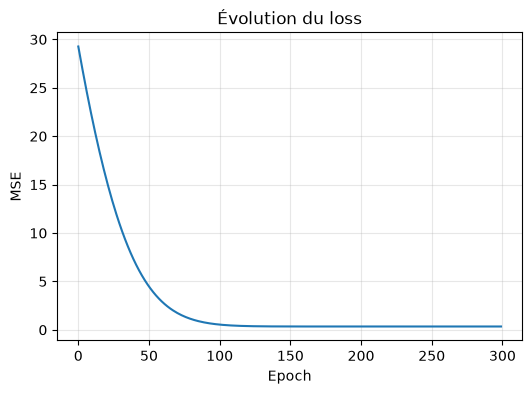

In [23]:
plt.figure(figsize=(6,4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Évolution du loss")
plt.grid(True, alpha=0.3)
plt.show()

<string>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


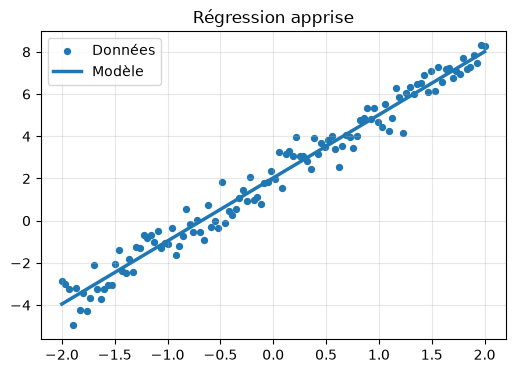

In [24]:
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X)

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.numpy(), linewidth=2.5, label="Modèle")
plt.legend()
plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

In [25]:
from torcheval.metrics import R2Score
metric = R2Score()
metric.update(y_hat,y)
r2=metric.compute()
print(f"R2 Score = {r2:.3f}")

R2 Score = 0.972


C:\Users\legen\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


# Partie pratique 2 — Classification

Créons deux classes de points en 2D.

<string>:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


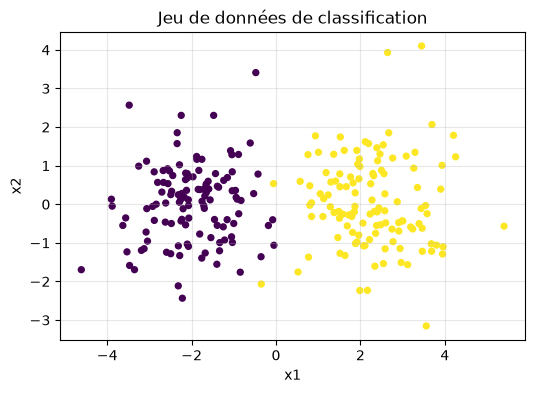

In [26]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long)
])

plt.figure(figsize=(6,4))
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Jeu de données de classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 16. Modèle de classification

In [27]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier()
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

## 17. Entraînement de la classification

In [28]:
losses_cls = []

for epoch in range(250):
    model_cls.train()

    logits = model_cls(X_cls)
    loss = criterion_cls(logits, y_cls)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())

print("Dernier loss:", losses_cls[-1])

Dernier loss: 0.0006943687913008034


In [29]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(X_cls)
    pred = logits.argmax(dim=1)
    accuracy = (pred == y_cls).float().mean()

print(f"Accuracy = {accuracy.item()*100:.2f}%")

Accuracy = 100.00%


Accuracy = 1.0000, recall= 1.0000, precision=1.0000, f1score=1.0000
tensor([[120,   0],
        [  0, 120]])


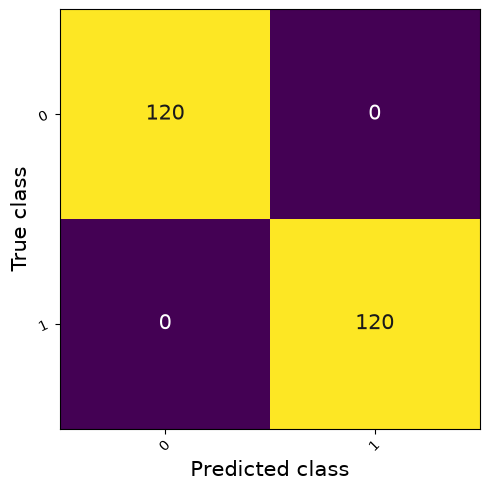

In [30]:
from torcheval.metrics import BinaryAccuracy, BinaryRecall, BinaryPrecision, BinaryPrecision, BinaryF1Score
from torchmetrics.classification import MulticlassConfusionMatrix, BinaryConfusionMatrix
accuracy_metric = BinaryAccuracy()
accuracy_metric.update(y_cls,pred)
accuracy_value = accuracy_metric.compute()

recall_metric = BinaryRecall()
recall_metric.update(y_cls, pred)
recall_value = recall_metric.compute()

precision_metric = BinaryPrecision()
precision_metric.update(y_cls,pred)
precision_value = precision_metric.compute()

f1_score_metric = BinaryF1Score()
f1_score_metric.update(y_cls, pred)
f1_score_value = f1_score_metric.compute()
print(f"Accuracy = {accuracy_value:.4f}, recall= {recall_value:.4f}, precision={precision_value:.4f}, f1score={f1_score_value:.4f}")

metric = BinaryConfusionMatrix()
confusion_matrix = metric(pred, y_cls)
print(confusion_matrix)
metric.plot()

## Visualisation de la frontière de décision

<string>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


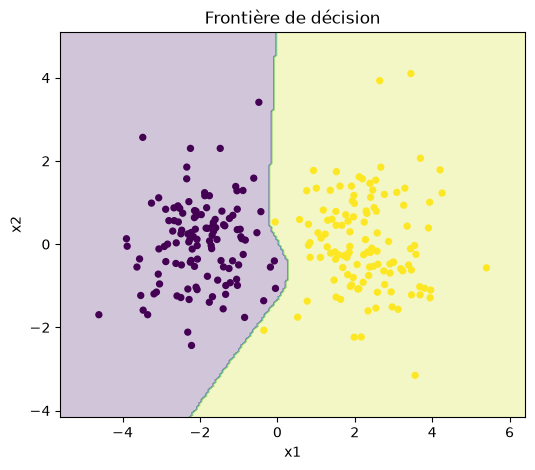

In [31]:
x1_min, x1_max = X_cls[:,0].min()-1, X_cls[:,0].max()+1
x2_min, x2_max = X_cls[:,1].min()-1, X_cls[:,1].max()+1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing='ij'
)

grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape)

plt.figure(figsize=(6,5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

## 18. Sauvegarder et recharger un modèle

In [32]:
path = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), path)
print("Modèle sauvegardé dans", path)

new_model = Classifier()
new_model.load_state_dict(torch.load(path, weights_only=True))
new_model.eval()

with torch.inference_mode():
    pred_new = new_model(X_cls).argmax(dim=1)

print("Prédictions identiques:", torch.equal(pred, pred_new))

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions identiques: True


# Synthèse

Les briques essentielles de PyTorch sont maintenant en place :

1. `Tensor`
2. `nn.Module`
3. `forward()`
4. fonction de coût
5. `optimizer.zero_grad()`
6. `loss.backward()`
7. `optimizer.step()`
8. `train()` / `eval()`
9. `Dataset` / `DataLoader`
10. sauvegarde avec `state_dict()`

Cette mécanique reste pratiquement la même pour des modèles plus avancés : CNN, Transformers, modèles génératifs ou PINNs.

# Exercices

### Exercice 1 : Régression

Prédire le salaire selon l’ancienneté et le niveau d’expertise

Objectif:

Construire un modèle de régression linéaire multiple pour prédire le salaire mensuel à partir de deux variables :
- Ancienneté : nombre d’années d’expérience.
- Niveau d’expertise : note de 1 à 5.
Le modèle doit apprendre la relation :

Salaire = w_1 * Ancienneté + w_2 * Expertise + b 

Les salaires sont exprimés en dirhams (DH). Les données sont fictives et servent uniquement à l’apprentissage.

1. *Générer les données*

Pour cet exercice, on suppose que les salaires suivent approximativement la règle : Salaire = 4000 + 600 * Ancienneté + 1500 * Expertise} + Bruit
Le bruit représente les variations individuelles non expliquées par les deux variables.

In [33]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé**

- Affichez les dimensions de X et de y.
- Calculez le salaire moyen.
- Tracez un nuage de points représentant le salaire selon l’ancienneté, avec une couleur différente selon l’expertise.


Dimensions de X (entrées) : torch.Size([300, 2])
Dimensions de y (cibles)  : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


<string>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


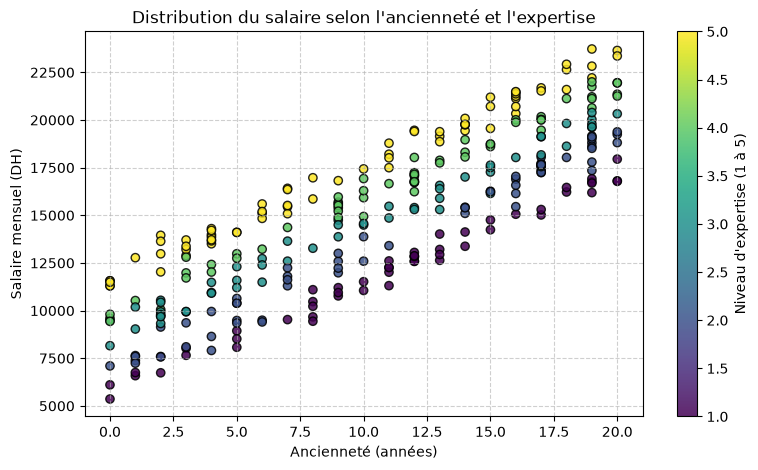

In [34]:
# Exploration des données et visualisations
print(f"Dimensions de X (entrées) : {X.shape}")
print(f"Dimensions de y (cibles)  : {y.shape}")
salaire_moyen = y.mean().item()
print(f"Salaire moyen : {salaire_moyen:.2f} DH")

# Nuage de points
plt.figure(figsize=(9, 5))
scatter = plt.scatter(
    X[:, 0].numpy(), 
    y[:, 0].numpy(), 
    c=X[:, 1].numpy(), 
    cmap="viridis", 
    alpha=0.85, 
    edgecolors="k"
)
cbar = plt.colorbar(scatter)
cbar.set_label("Niveau d'expertise (1 à 5)")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("Distribution du salaire selon l'ancienneté et l'expertise")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

2. *Séparer et préparer les données*
Utilisez 80 % des données pour l’entraînement et 20 % pour le test.

Pour faciliter l’apprentissage :

standardisez les entrées à partir des statistiques du jeu d’entraînement ;
exprimez les salaires en milliers de DH.

In [35]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

3. *Construire et entraîner le modèle*

In [36]:
# Deux variables d'entrée (ancienneté, expertise) et une sortie (salaire)
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

historique = []

model.train()

for epoch in range(500):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Époque {epoch + 1:3d} | Perte (MSE) : {loss.item():.4f}")

Époque 100 | Perte (MSE) : 0.2391
Époque 200 | Perte (MSE) : 0.2391
Époque 300 | Perte (MSE) : 0.2391
Époque 400 | Perte (MSE) : 0.2391
Époque 500 | Perte (MSE) : 0.2391


Travail demandé :

- Complétez le modèle et la boucle d’entraînement.
- Tracez l’évolution de la perte :


<string>:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


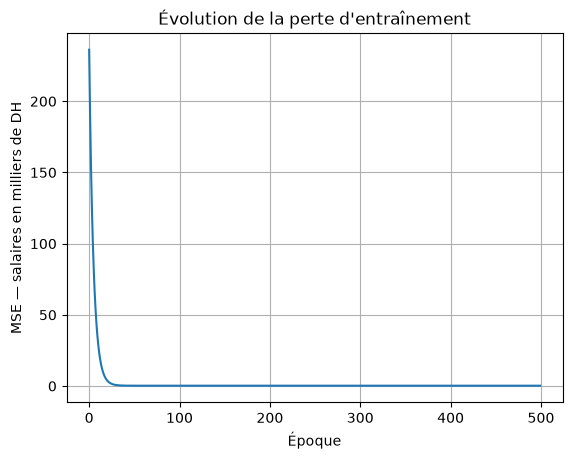

In [37]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

4. Évaluer les prédictions

In [38]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH (les cibles étaient divisées par 1000)
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # Calcul de la Mean Absolute Error (MAE)
    mae = torch.mean(torch.abs(predictions_dh - salaires_reels_dh))

print(f"Erreur absolue moyenne (MAE) : {mae.item():.2f} DH")

Erreur absolue moyenne (MAE) : 381.64 DH


Interprétation : une MAE de 400 DH signifie que les prédictions s’écartent, en moyenne, de 400 DH des salaires réels.

5. Prédire le salaire d’un nouveau salarié

Prédisez le salaire d’une personne ayant :

- 7 ans d’ancienneté ;
- un niveau d’expertise de 4/5.

In [39]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    model.eval()
    salaire_predit_kdh = model(nouveau_salarie_norm)
    salaire_predit_dh = salaire_predit_kdh.item() * 1000

print(f"Salaire prédit pour 7 ans d'ancienneté et expertise 4/5 : {salaire_predit_dh:.2f} DH")
salaire_theorique = 4000 + 600 * 7 + 1500 * 4
print(f"Salaire théorique exact (sans bruit) : {salaire_theorique} DH")
print(f"Écart modèle vs formule théorique : {abs(salaire_predit_dh - salaire_theorique):.2f} DH")

Salaire prédit pour 7 ans d'ancienneté et expertise 4/5 : 14201.94 DH
Salaire théorique exact (sans bruit) : 14200 DH
Écart modèle vs formule théorique : 1.94 DH


Vérification : d’après la règle de génération, le salaire sans bruit est :

4000 + 600 * 7 + 1500 * 4 = 14200 DH

Votre prédiction devrait être proche de cette valeur.

Questions complémentaires :

- À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?
- Pourquoi la perte ne devient-elle pas exactement nulle ?
- Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?
- Quel effet aurait une augmentation du bruit sur la précision ?
- Retrouvez les coefficients en unités d’origine à partir des paramètres du modèle entraîné. Ils devraient être proches de 600, 1500 et 4000.

Remarque : traiter l’expertise comme une note numérique suppose que chaque passage d’un niveau au suivant a le même effet sur le salaire. Cette hypothèse simplifie l’exercice, mais doit être vérifiée avec des données réelles.

**1. Préparation des données**

In [40]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


**Réponses aux questions :**

1. **Que représentent les quatre colonnes de `X_train` ?**
   - Colonne 0 : Longueur des sépales (*sepal length en cm*).
   - Colonne 1 : Largeur des sépales (*sepal width en cm*).
   - Colonne 2 : Longueur des pétales (*petal length en cm*).
   - Colonne 3 : Largeur des pétales (*petal width en cm*).

2. **Pourquoi utilise-t-on `torch.long` pour les étiquettes ?**
   - En classification multi-classes sous PyTorch, la fonction de perte `nn.CrossEntropyLoss` attend des indices de classes entiers discrets sous forme de tenseur d'entiers 64 bits (`torch.long` ou `torch.int64`). Les flottants ne sont pas admis pour indexer les classes.

3. **Pourquoi ne faut-il pas ajuster le `StandardScaler` sur les données de test ?**
   - Pour éviter la **fuite d'information (*data leakage*)**. Les données de test simulent des données futures et inconnues du modèle en production. Calculer la moyenne et la variance sur le jeu de test contaminerait l'apprentissage avec des statistiques futures.

**2. Construire le réseau**

In [41]:
# Réseau de neurones à 1 couche cachée (4 entrées -> 16 neurones cachés -> 3 classes)
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

Attention : n’ajoutez pas de Softmax à la sortie. CrossEntropyLoss attend directement les scores bruts, appelés logits.

**3. Entraîner le modèle**

Complétez la boucle d’entraînement. Pour cet exercice, chaque itération utilise toutes les données d’entraînement.

In [42]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    # 1. Remettre les gradients à zéro
    optimizer.zero_grad()

    # 2. Calculer les scores prédits (logits)
    logits = model(X_train)

    # 3. Calculer la perte
    loss = criterion(logits, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


**4. Évaluer le classifieur**

Complétez le calcul des prédictions et de l’accuracy, c’est-à-dire la proportion de fleurs correctement classées.

In [43]:
model.eval()

with torch.no_grad():
    logits = model(X_test)

    # Sélectionner la classe au score maximal pour chaque fleur
    predictions = logits.argmax(dim=1)

    # Calculer la proportion de prédictions correctes
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le jeu de test Iris : {accuracy.item():.1%}")

Accuracy sur le jeu de test Iris : 100.0%


**5- Autres question :**

- Tracez la courbe de perte.
- Affichez une matrice de confusion.
- Comparez ce réseau à un modèle sans couche cachée : nn.Linear(4, 3).
- Prédisez l’espèce d’une nouvelle fleur de mesures [5.1, 3.5, 1.4, 0.2], après l’avoir normalisée avec le même scaler.

Rapport de classification :
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Comparaison : Accuracy modèle MLP (1 couche cachée) : 100.0% vs Modèle linéaire : 90.0%
Prédiction pour la nouvelle fleur [5.1, 3.5, 1.4, 0.2] -> Espèce : setosa (Classe 0)


<string>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


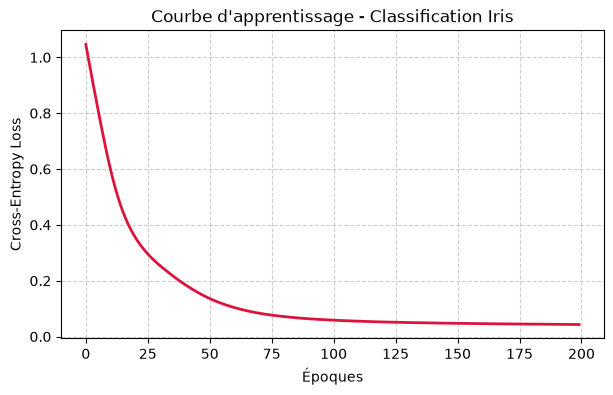

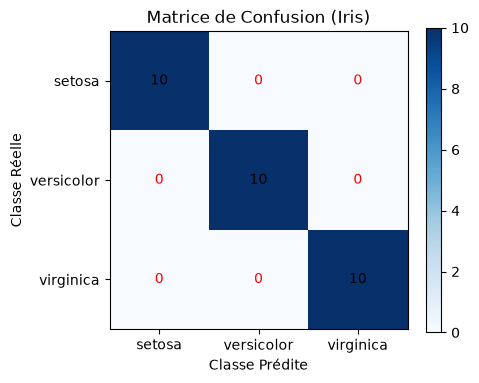

In [44]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

# 1. Courbe de perte
plt.figure(figsize=(7, 4))
plt.plot(losses, color="crimson", lw=2)
plt.title("Courbe d'apprentissage - Classification Iris")
plt.xlabel("Époques")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 2. Matrice de confusion
cm = confusion_matrix(y_test.numpy(), predictions.numpy())
print("Rapport de classification :")
print(classification_report(y_test.numpy(), predictions.numpy(), target_names=iris.target_names))

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.title("Matrice de Confusion (Iris)")
plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="red" if i != j else "black")
plt.xlabel("Classe Prédite")
plt.ylabel("Classe Réelle")
plt.colorbar()
plt.tight_layout()
plt.show()

# 3. Comparaison avec un modèle linéaire pur : nn.Linear(4, 3)
modele_lineaire = nn.Linear(4, 3)
opt_lin = torch.optim.Adam(modele_lineaire.parameters(), lr=0.01)
for _ in range(200):
    opt_lin.zero_grad()
    l = criterion(modele_lineaire(X_train), y_train)
    l.backward()
    opt_lin.step()

with torch.no_grad():
    acc_lin = (modele_lineaire(X_test).argmax(dim=1) == y_test).float().mean().item()
print(f"Comparaison : Accuracy modèle MLP (1 couche cachée) : {accuracy.item():.1%} vs Modèle linéaire : {acc_lin:.1%}")

# 4. Prédire l'espèce d'une nouvelle fleur [5.1, 3.5, 1.4, 0.2]
nouvelle_fleur = np.array([[5.1, 3.5, 1.4, 0.2]])
nouvelle_fleur_norm = torch.tensor(scaler.transform(nouvelle_fleur), dtype=torch.float32)

with torch.no_grad():
    logit_fleur = model(nouvelle_fleur_norm)
    classe_id = logit_fleur.argmax(dim=1).item()

print(f"Prédiction pour la nouvelle fleur [5.1, 3.5, 1.4, 0.2] -> Espèce : {iris.target_names[classe_id]} (Classe {classe_id})")

###  Exercice 3  — Classification des fleurs Iris 🌸

Objectif : entraîner un réseau de neurones pour prédire l’espèce d’une fleur à partir de quatre mesures :

- longueur et largeur des sépales ;
- longueur et largeur des pétales.

Le jeu de données Iris contient 150 fleurs réparties en trois classes : setosa, versicolor et virginica.


Bibliothèques : torch, scikit-learn.

### Exercice 2 : Classifier les chiffres MNIST
Objectif : utiliser des mini-lots et évaluer un modèle sur des données de test.

Chargement des données

In [45]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

#### Travail demandé : 
- Entraînez le modèle pendant 5 époques.
- Utilisez model.train() pendant l’entraînement.
- Évaluez-le avec model.eval() et torch.no_grad().
- Obtenez les classes prédites avec :
   - predicted_classes = outputs.argmax(dim=1)
   - Calculez mes métriques Accuracy, Recall, Precision et f1-Score sur le jeu de test.
   - Afficher la matrice de confusion
   - Affichez quelques images mal classées.
- Sauvegarder et recharger un modèle : réutiliser un réseau entraîné sans recommencer l’apprentissage.

Attention : CrossEntropyLoss attend les sorties brutes du réseau, sans Softmax, et des étiquettes entières.

Entraînement du MLP MNIST sur cpu pendant 1 époques...
Époque 1/1 - Perte : 0.3542

=== Métriques de Test MLP MNIST ===
Accuracy  : 93.99%
Precision : 0.9399
Recall    : 0.9391
F1-Score  : 0.9391
Modèle sauvegardé avec succès dans 'mlp_mnist.pth'
Modèle rechargé avec succès et prêt à l'inférence !


<string>:77: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:86: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


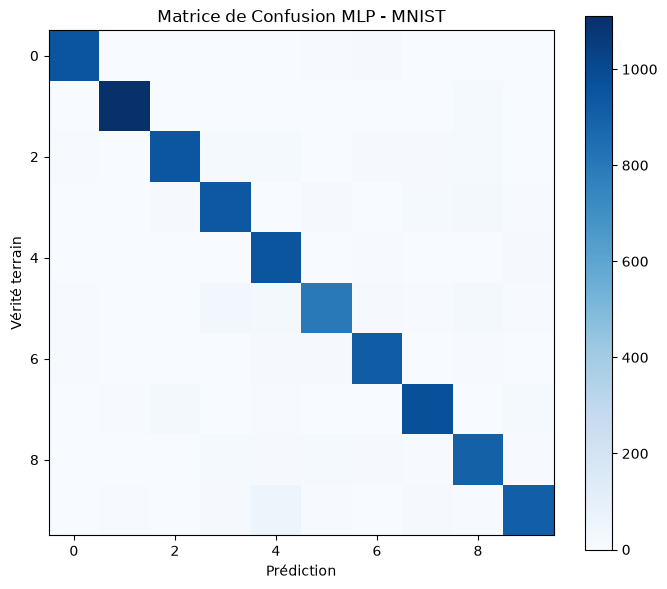

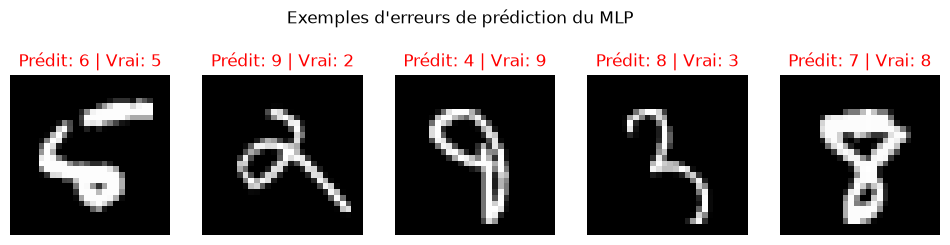

In [46]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

epochs = 5
print(f"Entraînement du MLP MNIST sur {device} pendant {epochs} époques...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_dataset)
    print(f"Époque {epoch + 1}/{epochs} - Perte : {epoch_loss:.4f}")

# Évaluation sur le jeu de test
model.eval()
all_preds = []
all_labels = []
misclassified_images = []
misclassified_preds = []
misclassified_true = []

with torch.no_grad():
    for images, labels in test_loader:
        images_dev = images.to(device)
        outputs = model(images_dev)
        preds = outputs.argmax(dim=1).cpu()

        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())

        # Détecter quelques erreurs
        mask = (preds != labels)
        if mask.sum().item() > 0 and len(misclassified_images) < 5:
            for img, p, t in zip(images[mask], preds[mask], labels[mask]):
                misclassified_images.append(img.squeeze().numpy())
                misclassified_preds.append(p.item())
                misclassified_true.append(t.item())
                if len(misclassified_images) >= 5:
                    break

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average='macro')
rec = recall_score(all_labels, all_preds, average='macro')
f1 = f1_score(all_labels, all_preds, average='macro')

print("\n=== Métriques de Test MLP MNIST ===")
print(f"Accuracy  : {acc:.2%}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")

# Matrice de confusion
plt.figure(figsize=(7, 6))
cm_mnist = confusion_matrix(all_labels, all_preds)
plt.imshow(cm_mnist, cmap="Blues")
plt.title("Matrice de Confusion MLP - MNIST")
plt.xlabel("Prédiction")
plt.ylabel("Vérité terrain")
plt.colorbar()
plt.tight_layout()
plt.show()

# Affichage de quelques erreurs
fig, axes = plt.subplots(1, len(misclassified_images), figsize=(12, 3))
for ax, img, p, t in zip(axes, misclassified_images, misclassified_preds, misclassified_true):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Prédit: {p} | Vrai: {t}", color="red")
    ax.axis("off")
plt.suptitle("Exemples d'erreurs de prédiction du MLP")
plt.show()

# Sauvegarde et rechargement
torch.save(model.state_dict(), "mlp_mnist.pth")
print("Modèle sauvegardé avec succès dans 'mlp_mnist.pth'")

# Rechargement
nouveau_modele = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)
nouveau_modele.load_state_dict(torch.load("mlp_mnist.pth"))
nouveau_modele.eval()
print("Modèle rechargé avec succès et prêt à l'inférence !")

### Exercice 4 — Classification MNIST avec un CNN

Objectif : construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

MNIST contient 60 000 images d’entraînement et 10 000 images de test, en niveaux de gris, de taille 28 × 28 pixels.

**1. Chargement des données**

In [47]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Réponses aux questions :**

1. **Que représentent les quatre dimensions du tenseur `images` `(N, C, H, W)` ?**
   - `N` : Taille du lot (*batch size*), soit le nombre d'images traitées simultanément (ex: 64).
   - `C` : Nombre de canaux de couleur (*Channels*). Ici `C = 1` car les images MNIST sont en niveaux de gris.
   - `H` : Hauteur de l'image en pixels (*Height* = 28).
   - `W` : Largeur de l'image en pixels (*Width* = 28).

2. **Pourquoi mélanger les données d’entraînement (`shuffle=True`) ?**
   - Le mélange brise les corrélations d'ordre dans les données, évite que le modèle mémorise une séquence de classes, stabilise la descente de gradient stochastique (SGD/Adam) et assure que chaque mini-lot représente fidèlement la distribution globale.

**2. Visualiser quelques images**

Complétez l’affichage des étiquettes :

<string>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


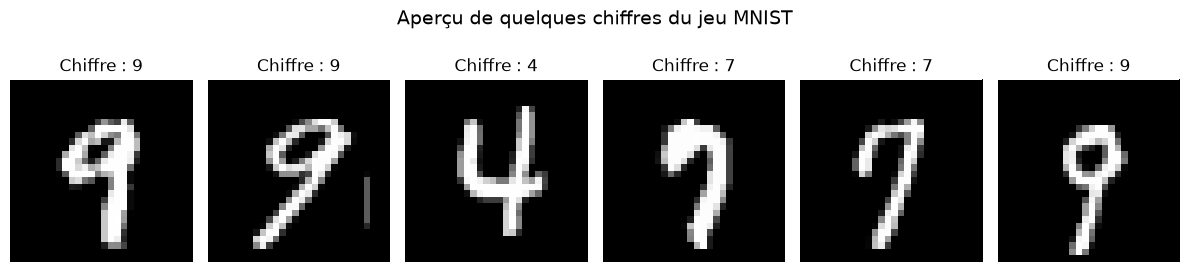

In [48]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

# Récupérer un premier lot
sample_images, sample_labels = next(iter(train_loader))

for i, ax in enumerate(axes):
    img = sample_images[i].squeeze().numpy()
    label = sample_labels[i].item()
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Chiffre : {label}", fontsize=12)
    ax.axis("off")

plt.suptitle("Aperçu de quelques chiffres du jeu MNIST", fontsize=14)
plt.tight_layout()
plt.show()

**3. Construire le CNN**

Implémentez cette architecture :

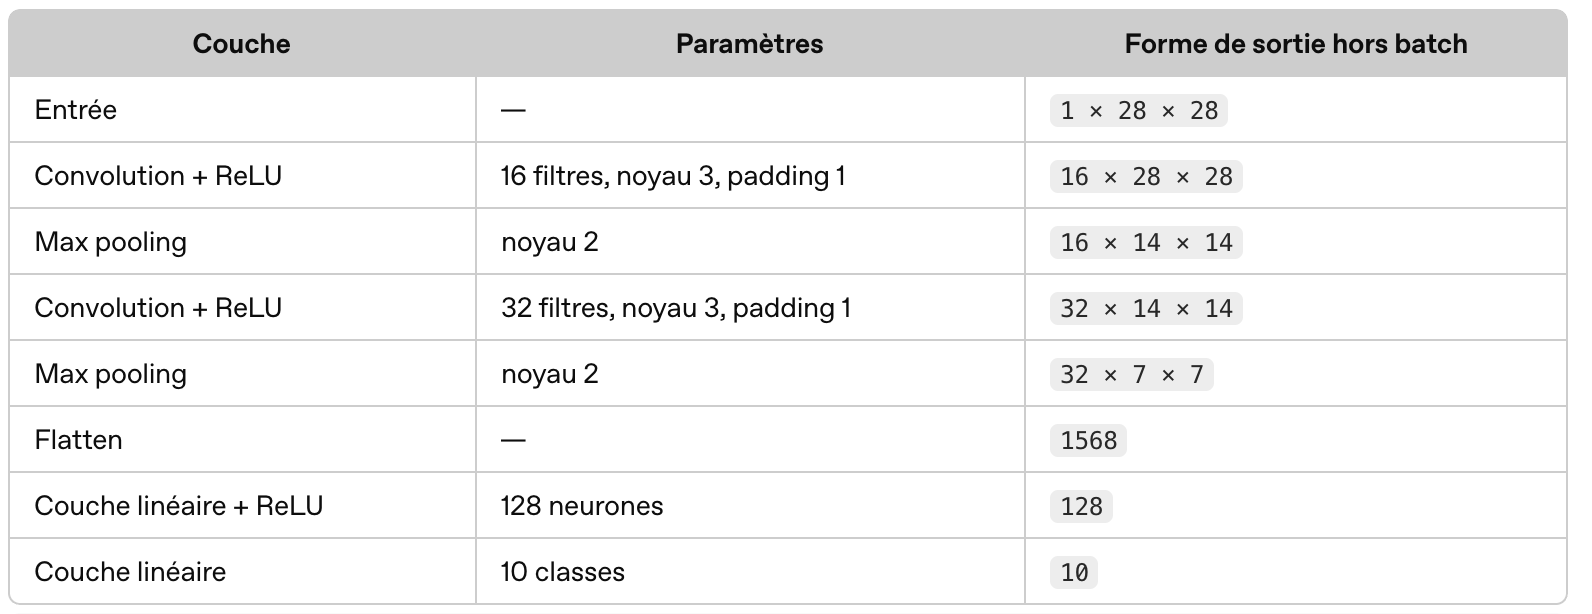

In [49]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Bloc 1 : 1 canal -> 16 filtres 3x3, padding 1 pour conserver 28x28
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 28x28 -> 14x14

            # Bloc 2 : 16 -> 32 filtres 3x3, padding 1
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)  # 14x14 -> 7x7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.25), # Régularisation Dropout
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MNISTClassifier().to(device)

# Vérifier la forme de sortie avec un batch d'exemple
sample_batch, _ = next(iter(train_loader))
with torch.no_grad():
    output = model(sample_batch.to(device))

assert output.shape == (sample_batch.size(0), 10)
print("Forme du tenseur de sortie :", output.shape)

Forme du tenseur de sortie : torch.Size([64, 10])


**Réponse à la question : Pourquoi la première couche linéaire reçoit-elle $32 \times 7 \times 7$ valeurs ?**

1. L'image d'entrée possède les dimensions $28 \times 28$ avec 1 canal.
2. Le premier bloc convolutionnel avec `padding=1` préserve la taille $28 \times 28$, puis le premier `MaxPool2d(2)` divise par 2 la hauteur et la largeur $\to 14 \times 14$ avec 16 canaux.
3. Le second bloc applique 32 filtres convolutionnels (avec padding), puis le second `MaxPool2d(2)` divise à nouveau par 2 $\to 7 \times 7$ avec 32 cartes d'activation (*feature maps*).
4. Lors de l'aplatissement (`nn.Flatten()`), les tenseurs de dimension $(32, 7, 7)$ sont vectorisés en un vecteur de longueur $32 \times 7 \times 7 = 1568$ valeurs.

**4. Entraîner le réseau**

In [50]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

print(f"Entraînement du CNN sur {device} pendant {epochs} époques...")

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Réinitialiser les gradients
        optimizer.zero_grad()

        # 2. Calculer les scores
        logits = model(images)

        # 3. Calculer la perte
        loss = criterion(logits, labels)

        # 4. Calculer les gradients
        loss.backward()

        # 5. Mettre à jour les paramètres
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)

    print(f"Époque {epoch + 1}/{epochs} | Perte moyenne : {average_loss:.4f}")

Entraînement du CNN sur cpu pendant 1 époques...
Époque 1/1 | Perte moyenne : 0.1940


**5. Évaluer sur le jeu de test**

In [51]:
model.eval()

correct = 0
total = 0

all_test_preds = []
all_test_labels = []
cnn_misclassified = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        # Classe ayant le score le plus élevé
        predictions = logits.argmax(dim=1)

        # Compter les bonnes prédictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        all_test_preds.extend(predictions.cpu().numpy())
        all_test_labels.extend(labels.cpu().numpy())

        # Collecter les erreurs pour affichage
        mask = (predictions != labels)
        if mask.sum().item() > 0 and len(cnn_misclassified) < 10:
            for img, p, t in zip(images[mask].cpu(), predictions[mask].cpu(), labels[mask].cpu()):
                cnn_misclassified.append((img.squeeze().numpy(), p.item(), t.item()))
                if len(cnn_misclassified) >= 10:
                    break

accuracy = correct / total
print(f"Accuracy du CNN sur le jeu de test : {accuracy:.2%}")

Accuracy du CNN sur le jeu de test : 98.29%


**Indices :**

- argmax(dim=1) sélectionne une classe pour chaque image ;
(predictions == labels).sum().item() compte les prédictions correctes.

- Résultat attendu : une accuracy généralement supérieure à 97 % après quelques époques, sans garantie exacte.

**Autres questions :**

- Affichez 10 images mal classées, avec leur vraie classe et la prédiction.
- Ajoutez une couche Dropout avant la dernière couche linéaire.
- Sauvegardez les paramètres avec torch.save(model.state_dict(), "mnist_cnn.pth").

Modèle CNN sauvegardé avec succès dans 'mnist_cnn.pth' !


<string>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


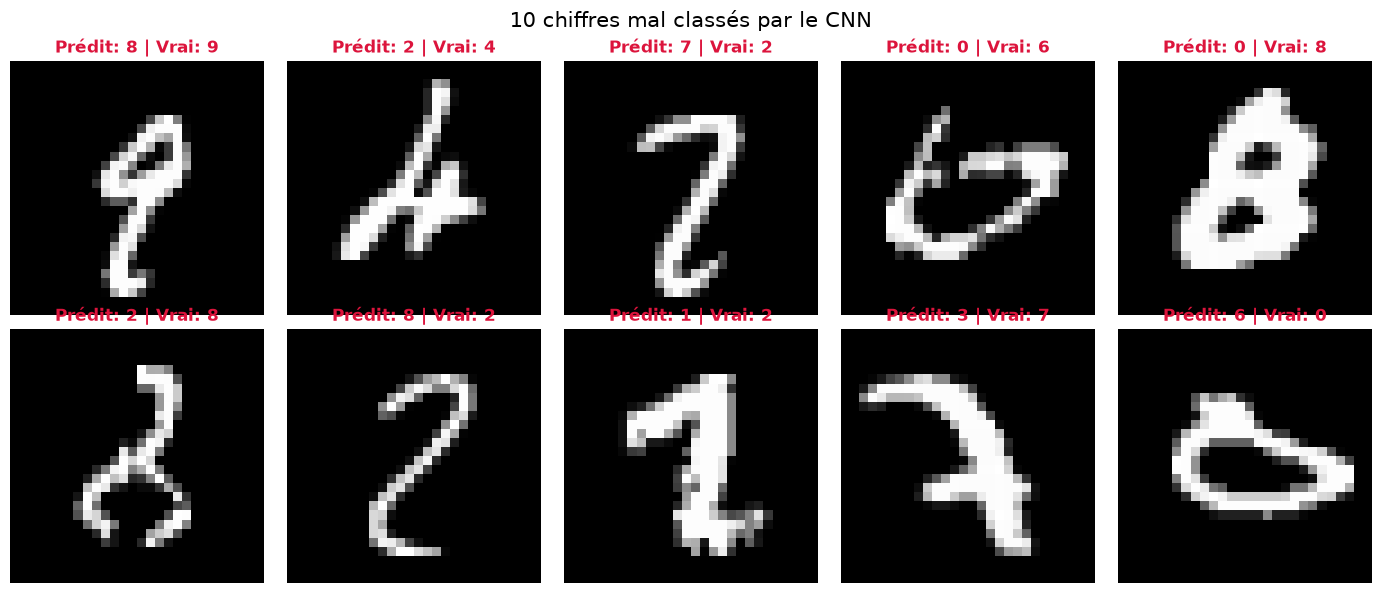

In [52]:
# 1. Afficher 10 images mal classées
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes = axes.flatten()

for i in range(min(10, len(cnn_misclassified))):
    img, p, t = cnn_misclassified[i]
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"Prédit: {p} | Vrai: {t}", color="crimson", fontweight="bold")
    axes[i].axis("off")

plt.suptitle("10 chiffres mal classés par le CNN", fontsize=15)
plt.tight_layout()
plt.show()

# 2. Sauvegarde du modèle CNN
torch.save(model.state_dict(), "mnist_cnn.pth")
print("Modèle CNN sauvegardé avec succès dans 'mnist_cnn.pth' !")